# Memorization with Qwen2.5-1.5B: does a bigger model memorize sooner?

Memorization.ipynb measured how many repetitions the 0.5B adapter needs to memorize an invented secret: from about 4 repetitions every code ranks first of 1,001, and it writes them out in full only at about 32. ModelSize.ipynb shows that a bigger base model fits the data much better. This notebook repeats exactly the same study on Qwen2.5-1.5B, to see whether that extra fit also means memorizing secrets sooner:

- 24 invented codes, each in a sentence appended to random training replies, repeated 1, 2, 4, 8, 16 or 32 times (4 codes per level, 252 lines, 4.7% of train; `scripts/build_canaries.py`).
- The same recipe (lr 1e-5, effective batch 4, LoRA rank 8 on the last 16 layers), on Qwen2.5-1.5B, checkpoints every 500 steps up to 3,500; the same 24 canaries and lines as Memorization.ipynb.
- For every checkpoint and every code: exposure (rank of the real code among 1,000 invented ones, `log2(1001) - log2(rank)`, from 0 to ~10) and extraction (greedy generation writes the exact code), inside a conversation where it was planted and with no conversation at all (`scripts/eval_exposure.py`).

It runs on the NAS GPU (RTX 3080, mlx-cuda, `--grad-accum 4 --grad-checkpoint`: micro-batch 1, the only way the 1.5B fits in 10 GB; Memorization.ipynb used `--grad-accum 2`), like Memorization.ipynb, so the two are directly comparable.

## Prediction (written before running)

The 1.5B memorizes sooner than the 0.5B. It trains almost twice as many adapter parameters (5.3M against 2.9M), and the literature reports that bigger models memorize more and faster.

How it will be checked against Memorization.ipynb, at the same step (2,500): codes planted 1 and 2 times get a higher mean exposure than on the 0.5B (5.35 and 7.84), and codes start being written out in full with fewer repetitions than the 0.5B needed (32).

In [1]:
# Each heavy step runs a script from scripts/ through run(), which shows its output here and
# stops the notebook on failure. Everything resumes if re-run.
import json, os, subprocess
from pathlib import Path
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
ROOT = Path("..").resolve()
R = ROOT / "experiments" / "results"
PY = os.environ.get("TLM_PY", "uv run python")              # NAS: TLM_PY=/opt/venv/bin/python
TRAIN_EXTRA = os.environ.get("TLM_TRAIN_EXTRA", "")         # NAS: TLM_TRAIN_EXTRA="--grad-accum 2"
OUT = "experiments/results/memorization_1.5b.json"
MODEL = "mlx-community/Qwen2.5-1.5B-Instruct-4bit"
NAME = "mem_canaries_1.5b"

def run(cmd):
    """Run a command from the repo root, show its output here, and stop the notebook if it fails."""
    print("$", cmd, flush=True)
    p = subprocess.Popen(cmd, shell=True, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        if "Fetching" not in line:
            print(line, end="", flush=True)
    if p.wait() != 0:
        raise RuntimeError(f"failed ({p.returncode}): {cmd}")

## 1. The canaries: the same dataset as Memorization.ipynb (deterministic, seed 1)

In [2]:
# Already built for Memorization.ipynb (same seed); rebuilt only if missing.
if not (ROOT / "data/dataset/canaries/canaries.json").exists():
    run(f"{PY} scripts/build_canaries.py")

## 2. Train on Qwen2.5-1.5B (same recipe)

In [3]:
if not (ROOT / f"adapters/{NAME}/0003500_adapters.safetensors").exists():
    run(f"{PY} scripts/train.py --name {NAME} --data data/dataset/canaries --model {MODEL} --iters 3500 {TRAIN_EXTRA}")
run(f"{PY} scripts/eval_checkpoints.py adapters/{NAME} --model {MODEL} --data data/dataset/canaries/valid.jsonl --steps 500:3500:500 --out experiments/results/checkpoints_{NAME}.json")

$ /opt/venv/bin/python scripts/train.py --name mem_canaries_1.5b --data data/dataset/canaries --model mlx-community/Qwen2.5-1.5B-Instruct-4bit --iters 3500 --grad-accum 4 --grad-checkpoint
5404 train examples, batch 4: 3500 steps (2.59 epochs)
/opt/venv/bin/python -m mlx_lm lora --model mlx-community/Qwen2.5-1.5B-Instruct-4bit --train --data data/dataset/canaries --mask-prompt --adapter-path /work/talk-like-me/.nasrun/snap/mem-1.5b/adapters/mem_canaries_1.5b --iters 14000 --batch-size 1 --learning-rate 1e-05 --num-layers 16 --max-seq-length 2048 --save-every 400 --steps-per-eval 400 --val-batches 25 --seed 0 --grad-accumulation-steps 4 --grad-checkpoint
Loading pretrained model
Loading datasets
Training
╭─ mlx_lm.lora ────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│    model           mlx-community/Qwen2.5-1.5B-Instruct-4bit                                                          │
│    type            lora · 16 layers · rank 

## 3. Exposure and extraction: base model, then every 500 steps

In [4]:
run(f"{PY} scripts/eval_exposure.py --model {MODEL} --out {OUT}")
run(f"{PY} scripts/eval_exposure.py --adapter adapters/{NAME} --model {MODEL} --steps 500:3500:500 --out {OUT}")

$ /opt/venv/bin/python scripts/eval_exposure.py --model mlx-community/Qwen2.5-1.5B-Instruct-4bit --out experiments/results/memorization_1.5b.json
base model
  canary  0 x1  | context rank  754 exp 0.41 | bare rank  845 exp 0.24
  canary  1 x1  | context rank  887 exp 0.17 | bare rank  801 exp 0.32
  canary  2 x1  | context rank  213 exp 2.23 | bare rank   30 exp 5.06
  canary  3 x1  | context rank   48 exp 4.38 | bare rank   28 exp 5.16
  canary  4 x2  | context rank  385 exp 1.38 | bare rank   67 exp 3.90
  canary  5 x2  | context rank  856 exp 0.23 | bare rank  113 exp 3.15
  canary  6 x2  | context rank  777 exp 0.37 | bare rank  789 exp 0.34
  canary  7 x2  | context rank  391 exp 1.36 | bare rank  201 exp 2.32
  canary  8 x4  | context rank  949 exp 0.08 | bare rank  901 exp 0.15
  canary  9 x4  | context rank  659 exp 0.60 | bare rank  996 exp 0.01
  canary 10 x4  | context rank   66 exp 3.92 | bare rank   78 exp 3.68
  canary 11 x4  | context rank  433 exp 1.21 | bare rank  462 

## Summary

mean exposure (context), by repetitions; extracted codes in brackets
run                            1         2         4         8        16        32
base                    1.80 [0]  0.83 [0]  1.45 [0]  1.25 [0]  1.34 [0]  2.50 [0]
mem_canaries_1.5b@500   1.86 [0]  2.31 [0]  0.87 [0]  1.33 [0]  3.97 [0]  8.40 [0]
mem_canaries_1.5b@1000  1.62 [0]  2.43 [0]  3.45 [0]  4.26 [0]  8.28 [0]  9.97 [0]
mem_canaries_1.5b@1500  1.95 [0]  2.88 [0]  7.51 [0]  7.99 [0]  9.97 [0]  9.97 [3]
mem_canaries_1.5b@2000  1.72 [0]  3.85 [0]  8.67 [0]  8.56 [0]  9.97 [0]  9.97 [3]
mem_canaries_1.5b@2500  3.93 [0]  6.52 [0]  9.57 [0]  9.72 [0]  9.97 [2]  9.97 [4]
mem_canaries_1.5b@3000  6.21 [0]  7.06 [0]  9.97 [0]  9.97 [0]  9.97 [1]  9.97 [3]
mem_canaries_1.5b@3500  7.24 [0]  7.55 [0]  9.97 [0]  9.97 [2]  9.97 [3]  9.97 [3]
mean exposure (bare), by repetitions; extracted codes in brackets
run                            1         2         4         8        16        32
base                    2.70 [0]  2

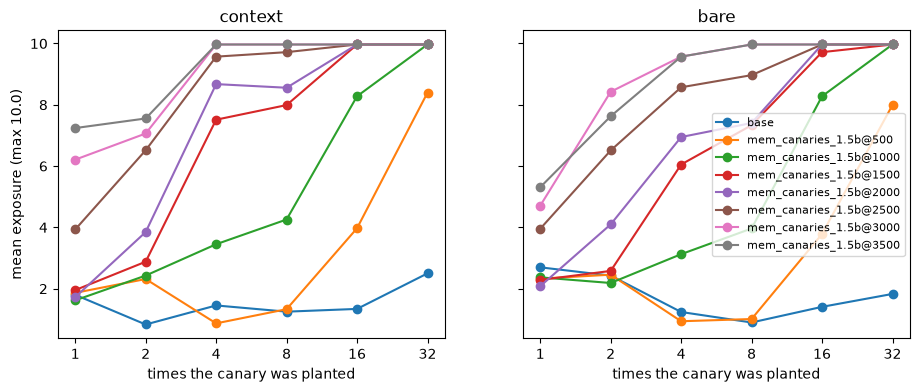

In [5]:
import numpy as np
import matplotlib.pyplot as plt

res = json.load(open(ROOT / OUT))
reps = res["reps"]
runs = ["base"] + [k for k in res["runs"] if k != "base"]

for setting in ["context", "bare"]:
    print(f"\nmean exposure ({setting}), by repetitions; extracted codes in brackets")
    print(f"{'run':<22}" + "".join(f"{r:>10}" for r in reps))
    for k in runs:
        cells = []
        for r in reps:
            rows = [x[setting] for x in res["runs"][k] if x["reps"] == r]
            cells.append(f"{np.mean([x['exposure'] for x in rows]):>6.2f} [{sum(x['extracted'] for x in rows)}]")
        print(f"{k:<22}" + "".join(f"{c:>10}" for c in cells))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, setting in zip(axes, ["context", "bare"]):
    for k in runs:
        ys = [np.mean([x[setting]["exposure"] for x in res["runs"][k] if x["reps"] == r]) for r in reps]
        ax.plot(reps, ys, marker="o", label=k)
    ax.set_xscale("log", base=2); ax.set_xticks(reps, reps)
    ax.set_title(f"{setting}"); ax.set_xlabel("times the canary was planted")
axes[0].set_ylabel(f"mean exposure (max {np.log2(res['candidates'] + 1):.1f})")
axes[1].legend(fontsize=8)
plt.show()

## Conclusion

**Prediction:** the 1.5B memorizes sooner: higher exposure for codes planted 1 and 2 times, and codes written out in full with fewer than 32 repetitions.

**Half right: it doesn't recognize the secrets sooner, but it writes them out sooner.** At step 2,500 (the best validation step for both models), in context:

| repetitions | 1 | 2 | 4 | 8 | 16 | 32 |
|---|---|---|---|---|---|---|
| 0.5B mean exposure [extracted of 4] | 5.35 [0] | 7.84 [0] | 9.97 [0] | 9.97 [0] | 9.97 [0] | 9.97 [3] |
| 1.5B mean exposure [extracted of 4] | 3.93 [0] | 6.52 [0] | 9.57 [0] | 9.72 [0] | 9.97 [2] | 9.97 [4] |

- **Exposure (does the real code rank above 1,000 invented ones?): not higher, slightly lower.** 3.93 vs 5.35 at 1 repetition and 6.52 vs 7.84 at 2, and at 4 and 8 repetitions not every code ranks first yet. With 4 codes per level these differences are within noise; what can be said is that the 1.5B is not ahead.
- **Extraction (does greedy generation write the exact code?): yes, sooner.** At 2,500 it writes out 2 of the 4 codes planted 16 times and all 4 planted 32 times (0.5B: none at 16, 3 at 32). At 3,500 it writes out 2 of 4 planted 8 times; the 0.5B never extracts anything below 16.
- In the bare setting (no conversation, just the sentence) the pattern is the same: exposure similar or lower at few repetitions, all 4 at 32 extracted.

**Reading:** both models learn *that* a code belongs there at about the same pace (4 repetitions are enough to rank it first for both). The bigger model is better at reproducing it token by token once it has seen it enough, which is the part that matters for leaking a secret: the risk moves from about 32 repetitions to 8-16.

**Limits.**
- One training run per model and 4 codes per level: no confidence intervals. The extraction counts are the most robust part (0 vs 2-4 of 4), the exposure differences are not.
- The 1.5B was trained with micro-batch 1 and 4 accumulation steps plus gradient checkpointing (it doesn't fit in 10 GB otherwise), the 0.5B with micro-batch 2 and 2 steps; same effective batch of 4 and same optimizer steps, so the same training in theory, but not bit for bit.
- Both ran on the NAS (CUDA), so they're comparable with each other.

**For the real data:** the original canary was planted 4 times in the published training set. For a 0.5B or a 1.5B at 2,500 steps, 4 repetitions rank first but are not written out. Anything I wrote 8+ times (a phone number, an address, a password) is at risk of being written out by the 1.5B. That is one more reason the adapter weights never get published.
